# Temporal and Vertical Patterns in Microbial ATP at Station ALOHA

### Research Questions:
#### How does microbial ATP concnetrations vary with depth and over time at the Station ALOHA?
 - Does microbial ATP change with pressure?
- Does microbial ATP change over time?
 - How do other biomass indicators such as phaeopigments and carbon values compare with ATP values?

#### Import Packages

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
import cmocean
import matplotlib.colors as mcolors
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import r2_score, mean_squared_error

## Data
This project uses water column data from the Hawaii Ocean Time series (HOT) program at the ALOHA station. This data set contains measurements collected during HOT cruises such as ATP measurements, CTD pressure, temperature, salinity, oxygen, and other biological variables. ATP concentrations are described in units of ng/kg and is used as a live microbial biomass proxy. CTD pressure is reported in dbar, which is converted using the approximation that 1 dbar is 1 m in depth.

The data were accessed through HOT-webODV and downloaded as a text file. The analysis is collected from 1988 to 2024. Mieruch, S. & Schlitzer, R., HOT-webODV, https://hot.webodv.awi.de , 2026.

In [2]:
raw_df = pd.read_csv("../DATA/ATP_depth_HOT_webODV.csv")
raw_df.info()


<class 'pandas.DataFrame'>
RangeIndex: 99432 entries, 0 to 99431
Data columns (total 20 columns):
 #   Column                                      Non-Null Count  Dtype  
---  ------                                      --------------  -----  
 0   Cruise                                      99432 non-null  int64  
 1   Station                                     99432 non-null  str    
 2   Type                                        99432 non-null  str    
 3   yyyy-mm-ddThh:mm:ss.sss                     99432 non-null  str    
 4   Longitude [degrees_east]                    99432 non-null  float64
 5   Latitude [degrees_north]                    99432 non-null  float64
 6   Site                                        99077 non-null  str    
 7   Site comments                               99077 non-null  str    
 8   Site lon/lat                                99312 non-null  float64
 9   Bottom depth [m]                            99077 non-null  float64
 10  Station Number       

In [3]:
# change the date from a string to a date data type and rename all the columns
raw_df["Date"] = pd.to_datetime(raw_df["yyyy-mm-ddThh:mm:ss.sss"])
raw_df = raw_df.rename(columns={
    "CTD Pressure (CTDPRS) [Decibars]": "Pressure",
    "CTD Temperature (CTDTMP) [ITS-90]": "Temp",
    "CTD Salinity (CTDSAL) [PSS-78]": "Salinity",
    "CTD Oxygen (CTDOXY) [umol/kg]": "DO",
    "Particulate Carbon (PC) [umol/kg]": "PC",
    "Pheopigments (Pheo) [ug/l]": "Pheo",
    "Adenosine 5'-Triphosphate (ATP) [ng/kg]": "ATP"})

print(raw_df.isna().sum())

Cruise                                            0
Station                                           0
Type                                              0
yyyy-mm-ddThh:mm:ss.sss                           0
Longitude [degrees_east]                          0
Latitude [degrees_north]                          0
Site                                            355
Site comments                                   355
Site lon/lat                                    120
Bottom depth [m]                                355
Station Number                                    0
Cast Number                                       0
Pressure                                         24
Temp                                            105
Salinity                                        105
DO                                              771
Dissolved Inorganic Carbon (DIC) [umol/kg]    92515
PC                                            95427
Pheo                                          89273
ATP         

In [4]:
# Examine non-null ATP values using the cruise dates, location, and any negative or zero values

atp_raw = raw_df[raw_df["ATP"].notna()].copy()
print("Date range:", atp_raw["Date"].min(), "to", atp_raw["Date"].max())
print("Latitude range:", atp_raw["Latitude [degrees_north]"].min(), "to", atp_raw["Latitude [degrees_north]"].max())

print("Longitude range:", atp_raw["Longitude [degrees_east]"].min(), "to", atp_raw["Longitude [degrees_east]"].max())

print("Pressure range (dbar):", atp_raw["Pressure"].min(), "to", atp_raw["Pressure"].max())

print("Unique cruises:", atp_raw["Cruise"].nunique())

print("Negative ATP count:", (atp_raw["ATP"] < 0).sum())
atp_raw[["ATP", "Pressure"]].describe()

Date range: 1988-11-01 20:36:00 to 2024-12-20 23:48:00
Latitude range: 22.605 to 22.876699
Longitude range: -158.146698 to -157.886703
Pressure range (dbar): 1.8 to 1046.19995
Unique cruises: 338
Negative ATP count: 9


,ATP,Pressure
count,3408.000000,3403.000000
mean,19.668718,180.942727
std,15.086865,220.967786
min,-1.400000,1.800000
25%,4.687500,45.100000
50%,19.835000,108.800000
75%,30.220000,248.800000
max,110.720000,1046.199950


In [5]:
# View the lowest 15 ATP values and create a new data frame with all valid positive ATP and Pressure values
display(atp_raw.sort_values("ATP").head(15))

atp_clean = atp_raw[(atp_raw["Pressure"].notna()) & (atp_raw["ATP"] > 0)].copy()
atp_clean["Year"] = atp_clean["Date"].dt.year
atp_clean["Month"] = atp_clean["Date"].dt.month
print("Clean ATP shape:", atp_clean.shape)

,Cruise,Station,Type,yyyy-mm-ddThh:mm:ss.sss,Longitude [degrees_east],Latitude [degrees_north],Site,Site comments,Site lon/lat,Bottom depth [m],...,Cast Number,Pressure,Temp,Salinity,DO,Dissolved Inorganic Carbon (DIC) [umol/kg],PC,Pheo,ATP,Date
95992,343,343_2_12_1,B,2023-08-11T23:51:00,-158.056702,22.758801,ALOHA,HOT Program open ocean station,-6.940659,4800.0,...,12,349.39999,11.3357,34.1366,160.00000,NaN,NaN,NaN,-1.40,2023-08-11 23:51:00
92652,331,331_2_11_1,B,2021-06-24T02:48:00,-158.015701,22.738300,ALOHA,HOT Program open ocean station,-6.967327,4800.0,...,11,353.39999,10.8050,34.1408,189.00000,NaN,NaN,NaN,-1.18,2021-06-24 02:48:00
96330,344,344_2_13_1,B,2023-09-17T23:50:00,-158.057007,22.731501,ALOHA,HOT Program open ocean station,-6.940659,4800.0,...,13,349.20001,10.2481,34.1078,180.30000,NaN,NaN,NaN,-1.12,2023-09-17 23:50:00
92907,332,332_2_11_1,B,2021-07-18T00:07:00,-157.931305,22.728201,ALOHA,HOT Program open ocean station,-6.967327,4800.0,...,11,350.79999,10.1937,34.0999,193.60001,NaN,NaN,NaN,-1.01,2021-07-18 00:07:00
95142,340,340_2_9_1,B,2023-01-25T17:45:00,-157.952301,22.684700,ALOHA,HOT Program open ocean station,-6.945055,4800.0,...,9,249.10001,17.6177,34.7431,192.39999,NaN,NaN,NaN,-0.87,2023-01-25 17:45:00
92650,331,331_2_11_1,B,2021-06-24T02:48:00,-158.015701,22.738300,ALOHA,HOT Program open ocean station,-6.967327,4800.0,...,11,252.30000,15.0934,34.4817,191.80000,NaN,NaN,NaN,-0.18,2021-06-24 02:48:00
93247,333,333_2_15_1,B,2021-10-30T23:56:00,-158.055496,22.704500,ALOHA,HOT Program open ocean station,-6.940659,4800.0,...,15,350.29999,10.1940,34.1098,172.70000,NaN,NaN,NaN,-0.17,2021-10-30 23:56:00
92906,332,332_2_11_1,B,2021-07-18T00:07:00,-157.931305,22.728201,ALOHA,HOT Program open ocean station,-6.967327,4800.0,...,11,249.10001,13.9109,34.3475,196.20000,NaN,NaN,NaN,-0.10,2021-07-18 00:07:00
95143,340,340_2_9_1,B,2023-01-25T17:45:00,-157.952301,22.684700,ALOHA,HOT Program open ocean station,-6.945055,4800.0,...,9,433.70001,8.5394,34.0468,139.00000,NaN,NaN,NaN,-0.02,2023-01-25 17:45:00
69014,248,248_2_12_1,B,2012-12-05T00:15:00,-158.048203,22.673500,ALOHA,HOT Program open ocean station,-6.940659,4800.0,...,12,350.20001,10.6993,34.1808,203.10001,NaN,NaN,NaN,0.00,2012-12-05 00:15:00


Clean ATP shape: (3393, 23)


## 1. Does microbial ATP change with pressure?
See if the microbial ATP distribution changes and how it varies across the CTD pressue (depth). Also highlight the different depth zones of the ocean to visualize any trends with depth zones.

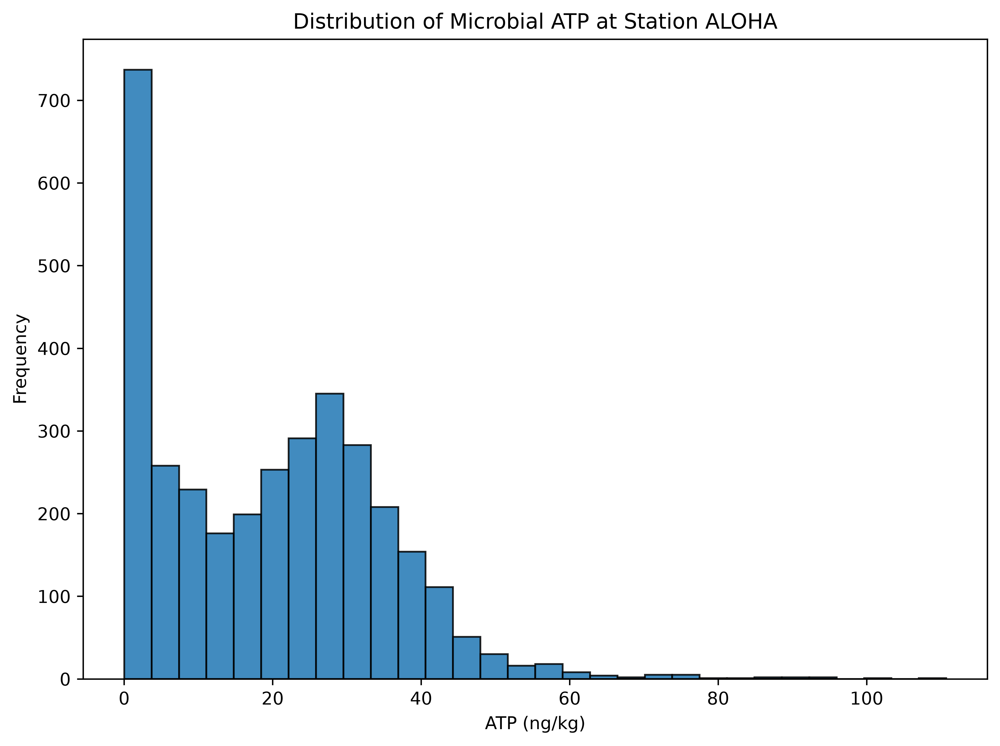

In [6]:
# Distribution of the cleaned ATP data
fig, ax = plt.subplots(1, figsize=(8, 6), dpi=600)

ax.hist(atp_clean["ATP"], bins = 30, edgecolor="black", alpha=0.85)

ax.set_title("Distribution of Microbial ATP at Station ALOHA")
ax.set_xlabel("ATP (ng/kg)")
ax.set_ylabel("Frequency")

plt.tight_layout()
plt.show()

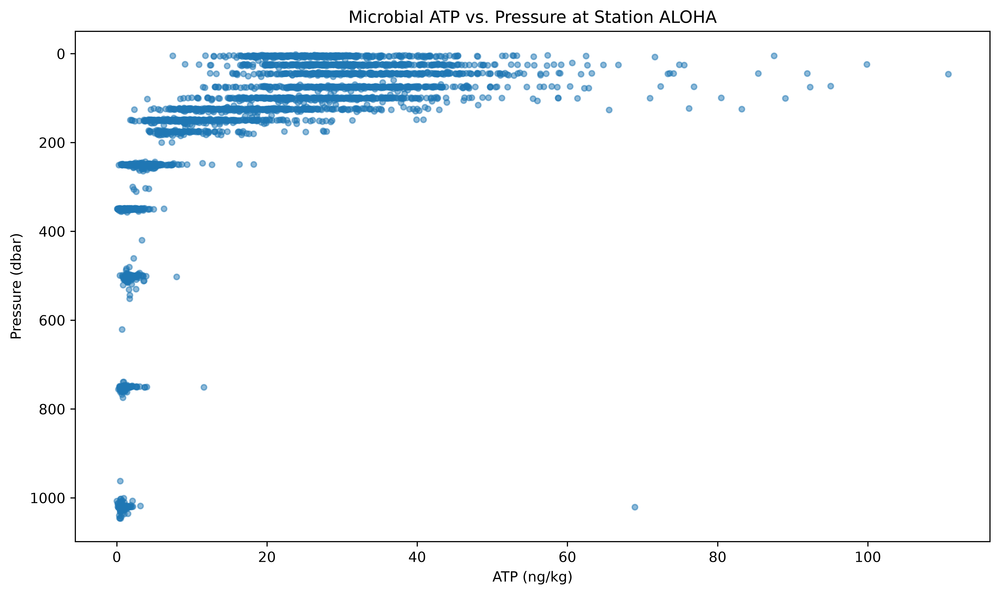

In [26]:
# Scatter plot of ATP with pressure
fig, ax = plt.subplots(1, figsize=(10, 6), dpi=600)

ax.scatter(atp_clean["ATP"], atp_clean["Pressure"], alpha=0.5, s=15)

ax.set_title("Microbial ATP vs. Pressure at Station ALOHA")
ax.set_xlabel("ATP (ng/kg)")
ax.set_ylabel("Pressure (dbar)")
ax.invert_yaxis()

plt.tight_layout()
plt.savefig("figure1.png", dpi=600, bbox_inches='tight')
plt.show()

In [8]:
# Bin into ocean depth zones and summarize statistics by those zones
zone_bins = [0, 150, 300, 500, 1100]
zone_labels = [
    "Euphotic (0–150 m)",
    "Upper Mesopelagic (150–300 m)",
    "Lower Mesopelagic (300–500 m)",
    "Bathypelagic (>500 m)"]
atp_clean["Depth_Zone"] = pd.cut(atp_clean["Pressure"],
                                bins=zone_bins,
                                labels=zone_labels,
                                include_lowest=True)
atp_clean.groupby("Depth_Zone", observed=False)["ATP"].agg(["count", "mean", "median", "std", "min", "max"])

,count,mean,median,std,min,max
Depth_Zone,,,,,,
Euphotic (0–150 m),2229,27.755182,27.230,12.041403,1.81,110.72
Upper Mesopelagic (150–300 m),617,6.948833,5.060,5.311986,0.28,31.37
Lower Mesopelagic (300–500 m),248,1.699113,1.555,0.989964,0.08,6.28
Bathypelagic (>500 m),299,1.505786,1.060,4.045641,0.01,68.99


In [9]:
# Upper 500m depth binning
depth_bins = [0, 25, 50, 75, 100, 125, 150, 175, 200, 250, 300, 350, 400, 500]
upper_500 = atp_clean[atp_clean["Pressure"] <= 500].copy()
upper_500["Depth_Bin"] = pd.cut(upper_500["Pressure"], bins=depth_bins, include_lowest=True)
upper_500.groupby("Depth_Bin", observed=False)["ATP"].agg(["count", "mean", "median", "std", "min", "max"])

,count,mean,median,std,min,max
Depth_Bin,,,,,,
"(-0.001, 25.0]",510,29.596588,27.915,10.009937,7.46,99.88
"(25.0, 50.0]",497,33.642213,31.650,11.268716,12.42,110.72
"(50.0, 75.0]",185,33.391081,32.820,11.246501,13.07,95.04
"(75.0, 100.0]",336,30.168244,29.890,10.004747,9.50,92.31
"(100.0, 125.0]",362,23.844033,22.685,11.039836,4.06,89.02
"(125.0, 150.0]",339,15.063245,13.650,7.943894,1.81,65.56
"(150.0, 175.0]",201,11.072935,10.000,5.665234,2.09,31.37
"(175.0, 200.0]",86,9.962442,8.645,4.717072,4.41,27.95
"(200.0, 250.0]",169,3.873314,3.490,2.419982,0.55,18.24


## 3. Does microbial ATP change over time?
See if sampling over the years has any noticable change and determine how the ATP changes in the wntire water column and with the upper photic zone. 

In [10]:
atp_clean.groupby("Year")["Cruise"].nunique()

Year
1988     2
1989     9
1990     8
1991    10
1992     9
1993     6
1994     9
1995     9
1996    10
1997    10
1998    12
1999    10
2000    11
2001    12
2002    10
2003    11
2004    12
2005    10
2006    12
2007    10
2008     8
2009    10
2010     9
2011    10
2012    10
2013    10
2014    10
2015    10
2016     9
2017    10
2018     8
2019     8
2020     8
2021     6
2022     5
2023     9
2024     6
Name: Cruise, dtype: int64

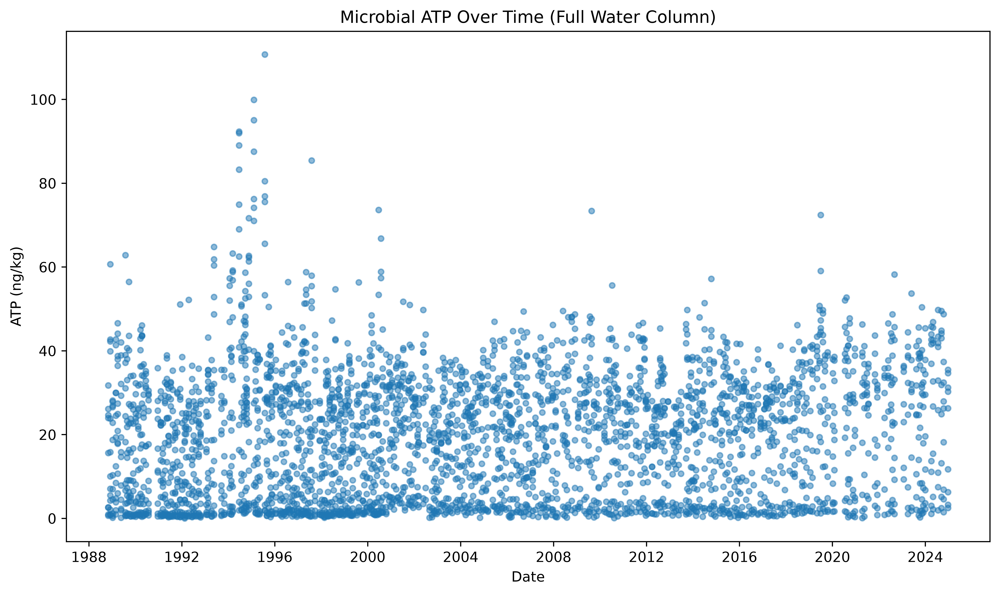

In [27]:
# Microbial ATP over time (full water column)
fig, ax = plt.subplots(1, figsize=(10, 6), dpi=600)

ax.scatter(atp_clean["Date"], atp_clean["ATP"], alpha=0.5, s=15)

ax.set_title("Microbial ATP Over Time (Full Water Column)")
ax.set_xlabel("Date")
ax.set_ylabel("ATP (ng/kg)")

plt.savefig("figure2a.png", dpi=600, bbox_inches='tight')
plt.tight_layout()
plt.show()

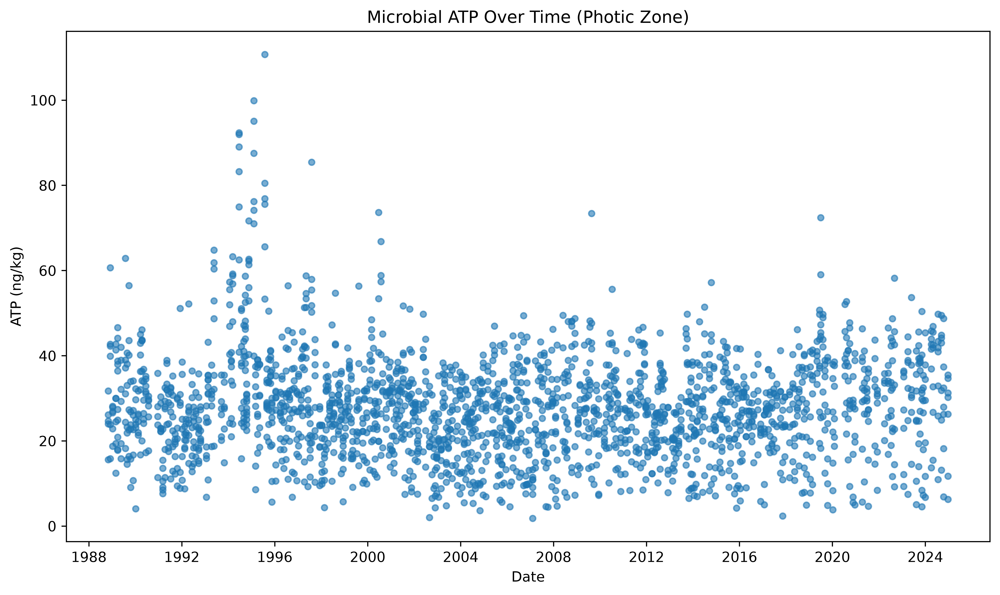

In [28]:
# ATP over time in the upper 150 dbar (~150 m)
shallow = atp_clean[atp_clean["Pressure"] <= 150].copy()

fig, ax = plt.subplots(1, figsize=(10, 6), dpi=600)
ax.scatter(shallow["Date"], shallow["ATP"], alpha=0.6, s=18)

ax.set_title("Microbial ATP Over Time (Photic Zone)")
ax.set_xlabel("Date")
ax.set_ylabel("ATP (ng/kg)")
plt.savefig("figure2b.png", dpi=600, bbox_inches='tight')
plt.tight_layout()
plt.show()

In [13]:
# Annual and monthly summary 
display(atp_clean.groupby("Year")["ATP"].agg(["count", "mean", "median", "std"]))
display(atp_clean.groupby("Month")["ATP"].agg(["count", "mean", "median", "std"]))

,count,mean,median,std
Year,,,,
1988,22,17.473182,12.800,17.325136
1989,109,17.607890,15.740,14.889366
1990,96,17.572604,17.260,14.176269
1991,119,13.979160,11.400,12.140484
1992,114,13.956579,14.600,11.454887
1993,77,18.941688,16.540,16.509337
1994,123,29.337642,26.730,23.056340
1995,119,25.043782,23.870,23.543385
1996,122,17.075820,13.935,14.130401


,count,mean,median,std
Month,,,,
1,243,16.944979,17.650,12.569351
2,289,18.172353,16.990,15.604652
3,298,19.543054,20.100,14.133142
4,269,20.498253,22.030,14.385231
5,316,20.206582,20.145,14.583973
6,248,22.138629,22.485,17.213433
7,317,22.253470,21.470,17.346321
8,296,20.853378,21.320,15.544530
9,256,21.079531,21.035,15.662246


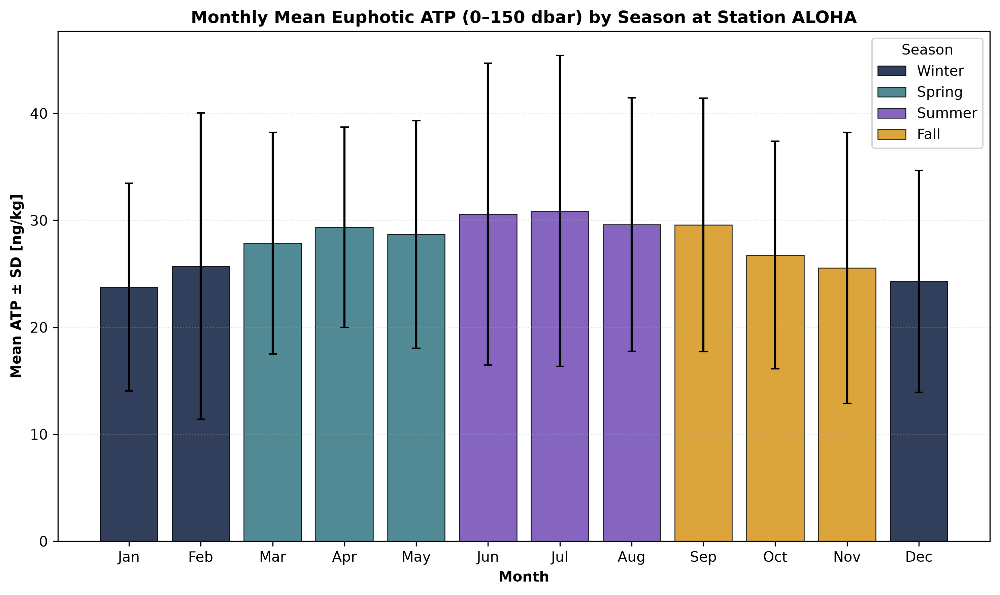

In [29]:
# Define meteorological seasons from Month
season_map = {
    12: "Winter", 1: "Winter", 2: "Winter",
    3: "Spring", 4: "Spring", 5: "Spring",
    6: "Summer", 7: "Summer", 8: "Summer",
    9: "Fall", 10: "Fall", 11: "Fall"}
season_order = ["Winter", "Spring", "Summer", "Fall"]
season_colors = {
    "Winter": "#1B2A4A",
    "Spring": "#3E7C88", 
    "Summer": "#7954BB",
    "Fall": "#D99B26"}

# Filter to Euphotic zone (0–150 dbar) so near-zero deep samples don't mask seasonal shifts
euphotic = atp_clean[atp_clean["Pressure"] <= 150].copy()
euphotic["Season"] = pd.Categorical(
    euphotic["Month"].map(season_map),
    categories=season_order,
    ordered=True)

monthly = euphotic.groupby(["Month", "Season"], observed=True)["ATP"].agg(["mean", "std", "count"]).reset_index()

fig, ax = plt.subplots(figsize=(10, 6), dpi=300)

for season in season_order:
    sub = monthly[monthly["Season"] == season]
    ax.bar(
        sub["Month"],
        sub["mean"],
        yerr=sub["std"],
        capsize=3,
        color=season_colors[season],
        edgecolor="black",
        linewidth=0.6,
        label=season,
        alpha=0.9)

ax.set_xticks(range(1, 13))
ax.set_xticklabels(["Jan", "Feb", "Mar", "Apr", "May", "Jun", "Jul", "Aug", "Sep", "Oct", "Nov", "Dec"])
ax.set_xlabel("Month", fontweight="bold")
ax.set_ylabel("Mean ATP ± SD [ng/kg]", fontweight="bold")
ax.set_title("Monthly Mean Euphotic ATP (0–150 dbar) by Season at Station ALOHA", fontweight="bold")
ax.legend(title="Season", frameon=True)
ax.grid(True, axis="y", linestyle=":", alpha=0.4)
plt.savefig("figure2c.png", dpi=600, bbox_inches='tight')
plt.tight_layout()
plt.show()

## 4. How do other biomass indicators such as phaeopigments and carbon values compare with ATP values? 
Clean carbon and phaeopigments and match them to the same cruise ATP observations within 20 dbars. Build a master spreadsheet and run linear comparisons. 

In [15]:
# clean the pc data
pc_df = raw_df[raw_df["PC"].notna() & (raw_df["PC"] > 0)].copy()
pc_df = pc_df[["Cruise", "Pressure", "PC"]].copy()

# merge the atp and carbon data
merged_pc = pd.merge(atp_clean, pc_df, on="Cruise", suffixes=("_atp", "_pc"))
merged_pc["depth_diff"] = (merged_pc["Pressure_atp"] - merged_pc["Pressure_pc"]).abs()

# bin them within 20m of one another
close_pc = merged_pc[merged_pc["depth_diff"] <= 20].copy()

list(close_pc.columns)

# rename PC
close_pc = close_pc.rename(columns={"PC_pc": "PC"})

# create an atp_pc dataframe with all of the attributes I want
atp_pc = close_pc[[ 
    "Cruise", 
    "Date", 
    "Cast Number",
    "Pressure_atp",
    "Pressure_pc",
    "depth_diff",
    "ATP",
    "DO",
    "PC"]].copy()


In [16]:
# clean the pheo data
pheo_df = raw_df[raw_df["Pheo"].notna() & (raw_df["Pheo"] > 0)].copy()
pheo_df = pheo_df[["Cruise", "Pressure", "Pheo"]].copy()

# merge the ATP and chla from the same cruise
merged_pheo = pd.merge(atp_clean, pheo_df, on="Cruise", suffixes=("_atp", "_pheo"))

# get the differences in depths to bin them within a specific distance of one another
merged_pheo["depth_diff_pheo"] = (merged_pheo["Pressure_atp"] - merged_pheo["Pressure_pheo"]).abs()

# bin them within 20m of one another
close_pheo = merged_pheo[merged_pheo["depth_diff_pheo"] <= 20].copy()

list(close_pheo.columns)

# rename PC
close_pheo = close_pheo.rename(columns={"Pheo_pheo": "Pheo"})

# create an atp_pc dataframe with all of the attributes I want
atp_pheo = close_pheo[[ 
    "Cruise", 
    "Date", 
    "Cast Number",
    "Pressure_atp",
    "Pressure_pheo",
    "depth_diff_pheo",
    "ATP",
    "DO",
    "Pheo"]].copy()


In [17]:
# create a master spreadsheet
atp_master = pd.merge(atp_pc, atp_pheo[["Cruise", "Cast Number", "Pressure_atp", "Pressure_pheo", "depth_diff_pheo", "Pheo"]], 
                      on=["Cruise", "Cast Number", "Pressure_atp"], how="left")

atp_master["Depth_Zone"] = pd.cut(atp_master["Pressure_atp"],
                                  bins=zone_bins,
                                  labels=zone_labels,
                                  include_lowest=True)
atp_master.info()

<class 'pandas.DataFrame'>
RangeIndex: 22270 entries, 0 to 22269
Data columns (total 13 columns):
 #   Column           Non-Null Count  Dtype         
---  ------           --------------  -----         
 0   Cruise           22270 non-null  int64         
 1   Date             22270 non-null  datetime64[us]
 2   Cast Number      22270 non-null  int64         
 3   Pressure_atp     22270 non-null  float64       
 4   Pressure_pc      22270 non-null  float64       
 5   depth_diff       22270 non-null  float64       
 6   ATP              22270 non-null  float64       
 7   DO               22096 non-null  float64       
 8   PC               22270 non-null  float64       
 9   Pressure_pheo    21288 non-null  float64       
 10  depth_diff_pheo  21288 non-null  float64       
 11  Pheo             21288 non-null  float64       
 12  Depth_Zone       22270 non-null  category      
dtypes: category(1), datetime64[us](1), float64(9), int64(2)
memory usage: 2.1 MB


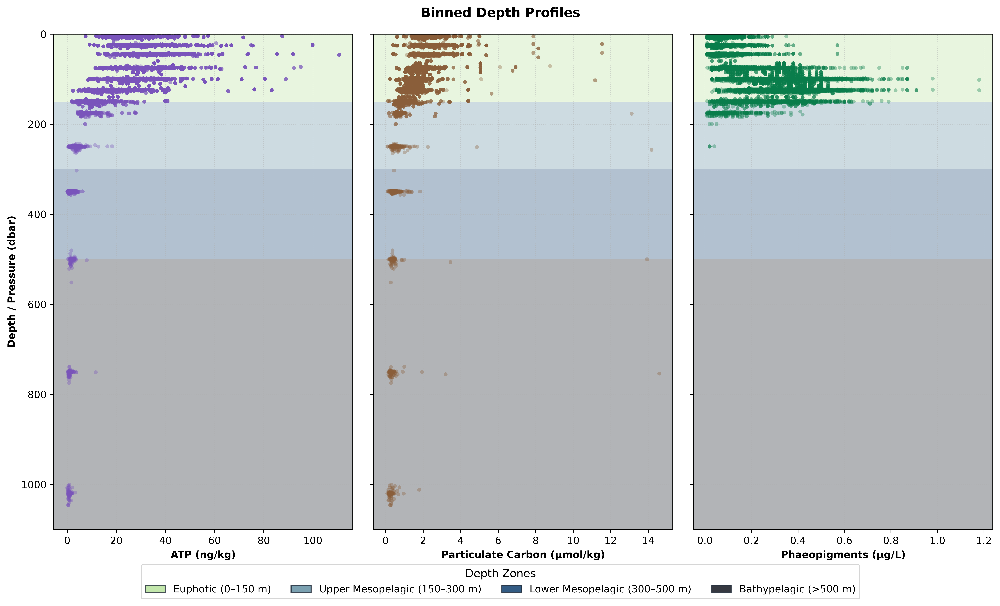

In [30]:
# Plot PC, Pheo, and ATP with depth

cols = ["Pressure_atp", "ATP", "PC", "Pheo", "DO", "Depth_Zone"]
data = atp_master[cols].dropna(subset=["Pressure_atp", "ATP", "PC", "DO"]).copy()

variables = [
    ("ATP", "ATP (ng/kg)", "#7954BBFF"),
    ("PC", r"Particulate Carbon ($\mathbf{\mu}$mol/kg)", "#8A5E3AFF"),
    ("Pheo", r"Phaeopigments ($\mathbf{\mu}$g/L)", "#097D4BFF")
]

zone_bounds = [0, 150, 300, 500, 1100]
zone_colors = [
    "#B4E197", 
    "#5A8A9E", 
    "#003366", 
    "#030712", ]

nrows, ncols = 1, 3
fig, axes = plt.subplots(nrows, ncols, figsize=(14, 8), dpi=600, sharey=True)

for i, (col_name, label, color) in enumerate(variables):
    ax = axes[i]
    
   
    for j in range(len(zone_bounds) - 1):
        ax.axhspan(zone_bounds[j], zone_bounds[j+1], facecolor=zone_colors[j], alpha=0.3, zorder=0)

    
    ax.scatter(
        data[col_name],
        data["Pressure_atp"],
        color=color,
        alpha=0.35,
        s=15,
        edgecolors="none",
        zorder=2
    )
    
    ax.set_xlabel(label, fontweight="bold")
    ax.grid(True, linestyle=":", alpha=0.5, zorder=1)

zone_patches = [
    mpatches.Patch(facecolor=zone_colors[j], alpha=0.8, linewidth=1.5, edgecolor="#1F2937", label=zone_labels[j])
    for j in range(len(zone_bounds) - 1)
]
legend = fig.legend(
    handles=zone_patches,
    title="Depth Zones",
    loc="upper center",
    bbox_to_anchor=(0.5, 0.02),
    ncol=4,
    frameon=True,
    facecolor="white",
    fancybox=True,
    fontsize=10,
    title_fontsize=11,
)
axes[0].invert_yaxis()
axes[0].set_ylim(1100, 0) # Focus cleanly on the upper 500 m where pigments/biomass live
axes[0].set_ylabel("Depth / Pressure (dbar)", fontweight="bold")
fig.suptitle("Binned Depth Profiles", fontsize=13, fontweight="bold")

plt.savefig("figure3.png", dpi=600, bbox_inches='tight')
plt.tight_layout()
plt.show()

In [19]:
# Make a regression for ATP and PC
reg_1d = atp_master[["PC", "ATP"]].dropna().copy()
X = reg_1d[["PC"]].to_numpy()
y = reg_1d["ATP"].to_numpy()
print(X.shape, y.shape)

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=4)

regr = LinearRegression()

regr.fit(X_train, y_train)

y_pred = regr.predict(X_test)

slope = regr.coef_[0]
intercept = regr.intercept_
mse = mean_squared_error(y_test, y_pred)
r2 = r2_score(y_test, y_pred)

print('y = %.2f * x + %.2f' % (slope, intercept))
print('Mean squared error: %.2f' % mse)
print('Coefficient of determination (R-squared): %.2f' % r2)

(22270, 1) (22270,)
y = 7.81 * x + 12.73
Mean squared error: 119.64
Coefficient of determination (R-squared): 0.22


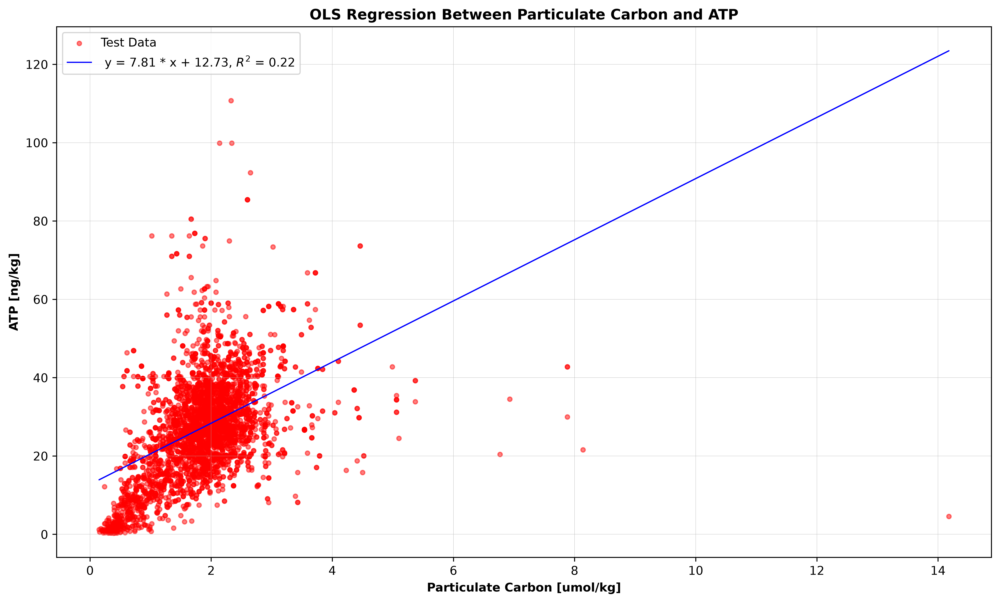

In [31]:
plt.figure(figsize=(14,8), dpi=600)
plt.scatter(X_test, y_test,  color='red', alpha=0.5, s=13, label='Test Data')
        
plt.plot(X_test, y_pred,  '-', color='blue', linewidth=1, label=f' y = {slope:.2f} * x + {intercept:.2f}, $R^2$ = {r2:.2f}')

plt.xlabel('Particulate Carbon [umol/kg]', fontweight='bold')
plt.ylabel('ATP [ng/kg]', fontweight='bold')
plt.legend(loc='upper left',
    frameon=True,
    fontsize=10)
plt.grid(True, linewidth= 0.2)
plt.title('OLS Regression Between Particulate Carbon and ATP', fontweight='bold')
plt.savefig("figure4a.png", dpi=600, bbox_inches='tight')
plt.show()

In [21]:
# Make a regression for ATP and Pheo
reg_1d2 = atp_master[["Pheo", "ATP"]].dropna().copy()
X2 = reg_1d2[["Pheo"]].to_numpy()
y2 = reg_1d2["ATP"].to_numpy()
print(X2.shape, y2.shape)

X2_train, X2_test, y2_train, y2_test = train_test_split(X2, y2, test_size=0.2, random_state=4)

regr2 = LinearRegression()
regr2.fit(X2_train, y2_train)

y2_pred = regr2.predict(X2_test)

slope2 = regr2.coef_[0]
intercept2 = regr2.intercept_

mse2 = mean_squared_error(y2_test, y2_pred)
r2_2 = r2_score(y2_test, y2_pred)

print('y = %.2f * x + %.2f' % (slope2, intercept2))
print('Mean squared error: %.2f' % mse2)
print('Coefficient of determination (R-squared): %.2f' % r2_2)

(21288, 1) (21288,)
y = -13.90 * x + 30.88
Mean squared error: 134.42
Coefficient of determination (R-squared): 0.03


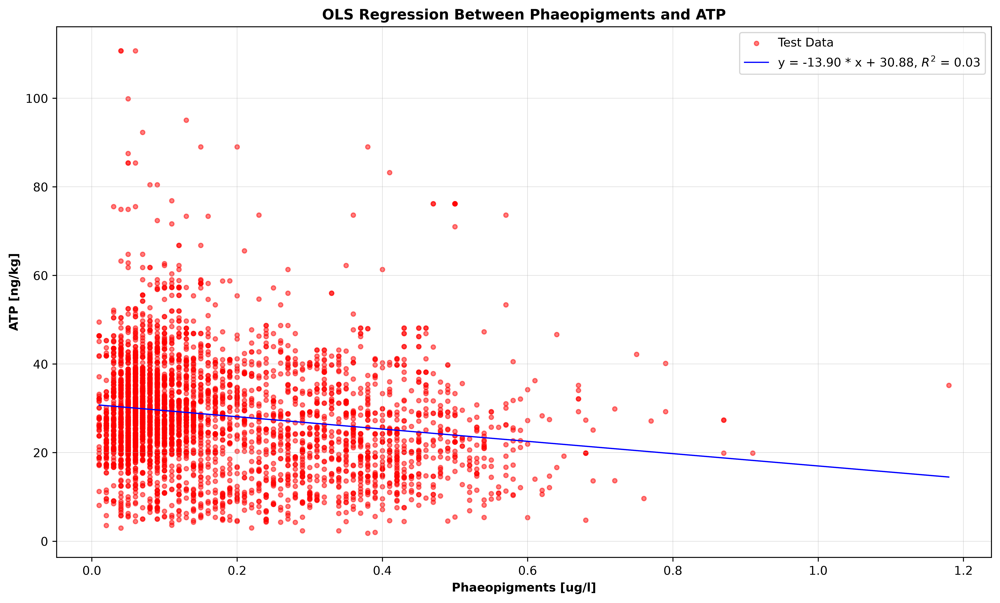

In [32]:
plt.figure(figsize=(14,8), dpi=600)
plt.scatter(X2_test, y2_test,  color='red', alpha=0.5, s=13, label='Test Data')
plt.plot(X2_test, y2_pred,  '-', color='blue', linewidth=1, label=f'y = {slope2:.2f} * x + {intercept2:.2f}, $R^2$ = {r2_2:.2f}')
plt.xlabel('Phaeopigments [ug/l]', fontweight='bold')
plt.ylabel('ATP [ng/kg]', fontweight='bold')
plt.legend(loc='upper right',
    frameon=True,
    fontsize=10)
plt.grid(True, linewidth= 0.2)
plt.title('OLS Regression Between Phaeopigments and ATP', fontweight='bold')
plt.savefig("figure4b.png", dpi=600, bbox_inches='tight')
plt.show()